Загружаем датасет

In [1]:
import os
import psycopg
import dotenv
import pandas as pd

connection = {"sslmode": "require", "target_session_attrs": "read-write"}
dotenv.load_dotenv()
postgres_credentials = {
    "host": os.getenv("DB_DESTINATION_HOST"),
    "port": os.getenv("DB_DESTINATION_PORT"),
    "dbname": os.getenv("DB_DESTINATION_NAME"),
    "user": os.getenv("DB_DESTINATION_USER"),
    "password": os.getenv("DB_DESTINATION_PASSWORD"),
}
assert all([var_value != "" for var_value in list(postgres_credentials.values())])

connection.update(postgres_credentials)
TABLE_NAME = "clean_flats_price"


with psycopg.connect(**connection) as conn:
    with conn.cursor() as cur:
        cur.execute(f"SELECT * FROM {TABLE_NAME}")
        data = cur.fetchall()
        columns = [col[0] for col in cur.description]


df = pd.DataFrame(data, columns=columns)


Разделяем на обучающую и тестовую выборку

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing  import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
import mlflow

dotenv.load_dotenv()
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_registry_uri("http://127.0.0.1:5000")

df = df[df['ceiling_height'] != 27]
X = df.drop(columns = ['price', 'building_id', 'studio'])
y = df['price']

cat_features = df.select_dtypes(['object']).columns.tolist()
cat_features.append("building_type_int")
train_size = 0.8
shuffle=True

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)

Будем тестировать наши преобразования с признаками на RandomForest и XGboost. 
Базовая модель имела такие показатели 

rmse: 2795542.821311236 <br>
mae: 2007594.9329998526 <br>
r2: 0.8019331564017734

In [3]:
from xgboost import XGBRegressor

experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id

def test_RandomForest(preproc, run_name, params):
    
    model = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2,
                              max_features="sqrt", random_state=42, n_jobs=-1)
    pipeline = Pipeline(
            [
                ('preprocessor', preproc),
                ('model', model)
            ]
        )
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    metrics = {
        "rmse": mean_squared_error(y_test, pred, squared=False),
        "mae": mean_absolute_error(y_test, pred),
        "r2": r2_score(y_test, pred)
    }
    print(metrics)
    with mlflow.start_run(experiment_id=experiment_id, run_name=run_name) as run:
        run_id = run.info.run_id
        mlflow.log_params(model.get_params())
        mlflow.log_params(params)
        mlflow.log_param("seed", 42)
        mlflow.log_param("shuffle", True)
        mlflow.log_param("train_size", 0.8)

        mlflow.log_metrics(metrics)
    return pipeline

def test_xgb(preproc, run_name, params):
    model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8,
        colsample_bytree=0.8, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=-1)
    pipeline = Pipeline(
                [
                    ('preprocessor', preproc),
                    ('model', model)
                ]
            )
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    
    metrics = {
        "rmse": mean_squared_error(y_test, pred, squared=False),
        "mae": mean_absolute_error(y_test, pred),
        "r2": r2_score(y_test, pred)
    }
    print(metrics)
    with mlflow.start_run(experiment_id=experiment_id, run_name=run_name) as run:
        run_id = run.info.run_id
        mlflow.log_params(model.get_params())
        mlflow.log_params(params)
        mlflow.log_param("seed", 42)
        mlflow.log_param("shuffle", True)
        mlflow.log_param("train_size", 0.8)

        mlflow.log_metrics(metrics)
    return pipeline


Посмотрим показатели XGboost только с кодированием категориальных признаков.

In [ ]:
preproc = ColumnTransformer([
        ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features)],
        remainder="passthrough",
        verbose_feature_names_out=False
    )

test_xgb(preproc, "xgb_basemodel", {"drop": "if_binary"})

{'rmse': 2594308.1184993205, 'mae': 1812872.803677014, 'r2': 0.8294221673292603}


2026/08/17 07:44:03 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


Посмотрим Kbins на признаке "build_year", будем делить на 5 интервалов

In [19]:
from sklearn.preprocessing import KBinsDiscretizer

n_bins = 5
strategy = 'quantile'
encode="onehot"
preprocessor = ColumnTransformer([
        ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features),
        ("Kbins", KBinsDiscretizer(n_bins=n_bins, strategy=strategy, encode=encode), ["build_year"])],
        remainder="passthrough",
        verbose_feature_names_out=False
    )
params = {
    "n_bins": 5, "strategy": "quantile", "encode": "onehot"
}
test_RandomForest(preprocessor, "RF_Kbins", params)
test_xgb(preprocessor, "XGB_Kbins", params)



{'rmse': 2792721.1149171074, 'mae': 2003122.2521323408, 'r2': 0.8023327957249345}
{'rmse': 2597870.9220698415, 'mae': 1813001.2319485506, 'r2': 0.8289533312545334}


KBinsDiscretizer не дало прироста в метриках при n_bins=5, проверим n_bins=10

In [20]:
n_bins = 10
strategy = 'quantile'
encode="onehot"
preprocessor = ColumnTransformer([
        ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features),
        ("Kbins", KBinsDiscretizer(n_bins=n_bins, strategy=strategy, encode=encode), ["build_year"])],
        remainder="passthrough",
        verbose_feature_names_out=False
    )
params = {
    "n_bins": 10, "strategy": "quantile", "encode": "onehot"
}
test_RandomForest(preprocessor, "RF_Kbins", params)
test_xgb(preprocessor, "XGB_Kbins", params)


{'rmse': 2829286.2898840327, 'mae': 2034495.4056987616, 'r2': 0.7971227857858945}
{'rmse': 2587818.3792044455, 'mae': 1808142.3546901946, 'r2': 0.8302745110056016}


Изменения совсем небольшие, проверим strategy='uniform'

In [21]:
n_bins = 10
strategy = 'uniform'
encode="onehot"
preprocessor = ColumnTransformer([
        ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features),
        ("Kbins", KBinsDiscretizer(n_bins=n_bins, strategy=strategy, encode=encode), ["build_year"])],
        remainder="passthrough",
        verbose_feature_names_out=False
    )
params = {
    "n_bins": 10, "strategy": "uniform", "encode": "onehot"
}
test_RandomForest(preprocessor, "RF_Kbins", params)
test_xgb(preprocessor, "XGB_Kbins", params)

/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:248: FutureWarning: In version 1.5 onwards, subsample=200_000 will be used by default. Set subsample explicitly to silence this warning in the mean time. Set subsample=None to disable subsampling explicitly.
  warnings.warn(


{'rmse': 2833334.2328126635, 'mae': 2035633.5711998874, 'r2': 0.796541845730178}


/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:248: FutureWarning: In version 1.5 onwards, subsample=200_000 will be used by default. Set subsample explicitly to silence this warning in the mean time. Set subsample=None to disable subsampling explicitly.
  warnings.warn(


{'rmse': 2592223.9891997855, 'mae': 1810417.7406124251, 'r2': 0.8296961235790724}


KBinsDiscretizer не привёл к улучшению метрик качества, а в некоторых случаях даже немного ухудшил результат

Проверим полиномиальыне преобразования на признаках `total_area`, `living_area`, `kitchen_area`, `rooms`, степень полинома 2

In [ ]:
from sklearn.preprocessing import PolynomialFeatures


poly_features = ["total_area", "living_area", "kitchen_area", "rooms"]

degree = 2
include_bias = False
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features),
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=include_bias, ), poly_features)],
    remainder="passthrough",
    verbose_feature_names_out=False
)
params = {"degree": 2, "include_bias": False}
test_RandomForest(preprocessor, "Poly_Rf", params)
test_xgb(preprocessor, "Poly_xgb", params)

{'rmse': 2887814.5847167755, 'mae': 2061054.3860279361, 'r2': 0.7886422906521722}
{'rmse': 2602256.833771405, 'mae': 1820087.122259177, 'r2': 0.8283752972602059}


Использование PolynomialFeatures не улучшило качество модели

Добавим новый признак расстояние до центра Москвы

In [ ]:
import numpy as np

CENTER_LAT = 55.7520
CENTER_LON = 37.6175

def haversine_distance(lat, lon):
    R = 6371  

    lat = np.radians(lat)
    lon = np.radians(lon)
    center_lat = np.radians(CENTER_LAT)
    center_lon = np.radians(CENTER_LON)

    dlat = lat - center_lat
    dlon = lon - center_lon

    a = np.sin(dlat / 2) ** 2 + np.cos(center_lat)* np.cos(lat) * np.sin(dlon / 2) ** 2
    

    return 2 * R * np.arcsin(np.sqrt(a))
df_copy = df.copy()
df_copy["distance_to_center"] = haversine_distance(
    df["latitude"],
    df["longitude"],
)
X = df_copy.drop(columns = ['price', 'building_id', "studio"])
y = df_copy['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)],
    remainder="passthrough",
    verbose_feature_names_out=False
)

test_RandomForest(preprocessor, "RF_distance_to_centre", {'distance_type': 'haversine'})
test_xgb(preprocessor, "XGB_distance_to_centre", {'distance_type': 'haversine'})

{'rmse': 2699401.090937041, 'mae': 1949638.03205632, 'r2': 0.8153223580051131}
{'rmse': 2568554.4814641154, 'mae': 1795515.4820152747, 'r2': 0.8327920022033329}


Есть прирост у RandomForest и небольшие улучшения в показателях XGboost

Проверим RobutScaler на признаках `kitchen_area`, `living_area`, `total_area`, `ceiling_height`, с quantile_range=(10, 90)

In [31]:
from sklearn.preprocessing import RobustScaler

X = df.drop(columns = ['price', 'building_id', 'studio'])
y = df['price']

cat_features = df.select_dtypes(['object']).columns.tolist()
cat_features.append("building_type_int")
train_size = 0.8
shuffle=True

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)

rob_feat = ['kitchen_area', 'living_area', 'total_area', 'ceiling_height']
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features),
        ("RobutScaler", RobustScaler(quantile_range=(10, 90)), rob_feat),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
test_RandomForest(preprocessor, "RF_RobutScaler", {"quantile_range": (10, 90)})
test_xgb(preprocessor, "XGB_RobutScaler", {"quantile_range": (10, 90)})

{'rmse': 2753443.0493109915, 'mae': 1976811.318163147, 'r2': 0.8078538535299424}
{'rmse': 2584281.570739952, 'mae': 1804073.124091525, 'r2': 0.8307381264902303}


Небольшие улучшения в показателях моделей

Посмотрим теперь на автоматическую генерацию признаков с помощью библиотеки autofeat

In [4]:
from autofeat import AutoFeatRegressor

autofeat_cols = [
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "floor",
    "floors_total",
    "flats_count",
    "ceiling_height",
]
transformations = ["1/", "log",  "sqrt"]

auto = AutoFeatRegressor(
    feateng_steps=2,
    transformations=transformations,
    max_gb=10,
    feateng_cols=autofeat_cols
)

X = df.drop(columns = ['price', 'building_id', 'studio'])
y = df['price']
cat_features = df.select_dtypes(['object']).columns.tolist()
cat_features.append("building_type_int")
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)

# auto.fit(X_train, y_train)
# X_test_fe = auto.transform(X_test)
# new_features = [col for col in X_test_fe.columns if col not in X_train.columns]


In [13]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
)
preprocessor = ColumnTransformer(
    [
     ('auto', auto, autofeat_cols),
     ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

pipeline = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])
pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
}

print(metrics)

{'rmse': 2969787.960268683, 'mae': 2119510.6214361624, 'r2': 0.7764728055897637}


Логируем

In [14]:
with mlflow.start_run(experiment_id=experiment_id, run_name="RF_autofeat") as run:
    mlflow.log_params(model.get_params())
    mlflow.log_dict({"new_features" : new_features}, "features/autofeat_features.json")
    mlflow.log_metrics(metrics)
    mlflow.sklearn.log_model(preprocessor, artifact_path="preprocessor")

2026/08/17 20:03:06 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


XGboost

In [8]:
model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8,
        colsample_bytree=0.8, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=-1)

preprocessor = ColumnTransformer(
    [
     ('auto', auto, autofeat_cols),
     ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
pipeline = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])
pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
}

print(metrics)

{'rmse': 2597729.8265207754, 'mae': 1821008.804241603, 'r2': 0.8289719105211604}


Изменения почти незаметные, возможно на этапе отбора признаков какаие-то из них будут полезны.

Залогируем результат.

In [ ]:
with mlflow.start_run(experiment_id=experiment_id, run_name="XGB_autofeat") as run:
    mlflow.log_params(model.get_params())
    mlflow.log_dict({"new_features" : new_features}, "features/autofeat_features.json")
    mlflow.log_metrics(metrics)
    mlflow.sklearn.log_model(preprocessor, artifact_path="preprocessor")

2026-08-17 18:11:13,003 INFO: Found credentials in environment variables.
2026/08/17 18:11:14 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


Теперь совместим RobutScaler, новый признак: расстояние до центра Москвы и признаки полученные с помощью autofeat

In [5]:
from sklearn.preprocessing import RobustScaler
import numpy as np


rob_feat = ['kitchen_area', 'living_area', 'total_area', 'ceiling_height']
autofeat_cols = [
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "floor",
    "floors_total",
    "flats_count",
    "ceiling_height",
]

preprocessor = ColumnTransformer(
    [('RobutScaler', RobustScaler(quantile_range=(10, 90)), rob_feat),
     ('auto', auto, autofeat_cols),
     ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

CENTER_LAT = 55.7520
CENTER_LON = 37.6175

def haversine_distance(lat, lon):
    R = 6371  

    lat = np.radians(lat)
    lon = np.radians(lon)
    center_lat = np.radians(CENTER_LAT)
    center_lon = np.radians(CENTER_LON)

    dlat = lat - center_lat
    dlon = lon - center_lon

    a = np.sin(dlat / 2) ** 2 + np.cos(center_lat)* np.cos(lat) * np.sin(dlon / 2) ** 2
    

    return 2 * R * np.arcsin(np.sqrt(a))

df_copy = df.copy()
df_copy["distance_to_center"] = haversine_distance(
    df["latitude"],
    df["longitude"],
)
X = df_copy.drop(columns = ['price', 'building_id', "studio"])
y = df_copy['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)
params = {
    'distance_type': 'haversine',
    "quantile_range": (10, 90)
}

RandomForest

In [6]:
import time

model = RandomForestRegressor(n_estimators=200 ,max_depth=20, min_samples_leaf=2, max_features="sqrt", random_state=42, n_jobs=-1)
rf_pipe = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])

start = time.perf_counter()
rf_pipe.fit(X_train, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = rf_pipe.predict(X_test)
predict_time = time.perf_counter() - start

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}


Логируем

In [7]:
pip_requirements = '../requirements.txt'
signature = mlflow.models.infer_signature(X_test, pred)
input_example = X_test[:10]
rf_model = rf_pipe.named_steps["model"]
with mlflow.start_run(experiment_id=experiment_id, run_name="rf_model_registry") as run:
    run_id = run.info.run_id
    mlflow.log_params(rf_model.get_params())
    mlflow.log_params(params)
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("train_size", 0.8)
    mlflow.log_param("model", "RandomForest")
    mlflow.log_metrics(metrics)

    model_info = mlflow.sklearn.log_model(sk_model=rf_pipe, pip_requirements=pip_requirements,
                                              signature=signature, input_example=input_example,
                                              registered_model_name="flats_price_model", artifact_path="models",
                                              await_registration_for=60)

/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/mlflow/models/signature.py:212: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  inputs = _infer_schema(model_input) if model_input is not None else None
2026-08-17 20:10:16,285 INFO: Found credentials in environment variables.
Successfully registered model 'flats_price_model'.
2026/08/17 2

XGboost

In [8]:
import time

model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8,
        colsample_bytree=0.8, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=-1)
xgb_pipe = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])

start = time.perf_counter()
xgb_pipe.fit(X_train, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = xgb_pipe.predict(X_test)
predict_time = time.perf_counter() - start

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}


In [9]:
pip_requirements = '../requirements.txt'
signature = mlflow.models.infer_signature(X_test, pred)
input_example = X_test[:10]
xgb_model = xgb_pipe.named_steps["model"]
with mlflow.start_run(experiment_id=experiment_id, run_name="xgb_model_registry") as run:
    run_id = run.info.run_id
    mlflow.log_params(xgb_model.get_params())
    mlflow.log_params(params)
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("train_size", 0.8)
    mlflow.log_param("model", "XGboost")
    mlflow.log_metrics(metrics)

    model_info = mlflow.sklearn.log_model(sk_model=xgb_pipe, pip_requirements=pip_requirements,
                                              signature=signature, input_example=input_example,
                                              registered_model_name="flats_price_model", artifact_path="models",
                                              await_registration_for=60)

/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/mlflow/models/signature.py:212: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  inputs = _infer_schema(model_input) if model_input is not None else None
Registered model 'flats_price_model' already exists. Creating a new version of this model...
2026/08/17 20:13:47 INFO mlflow.tracking._mo

XGboost показал лучше результаты и в метриках, и в производительности 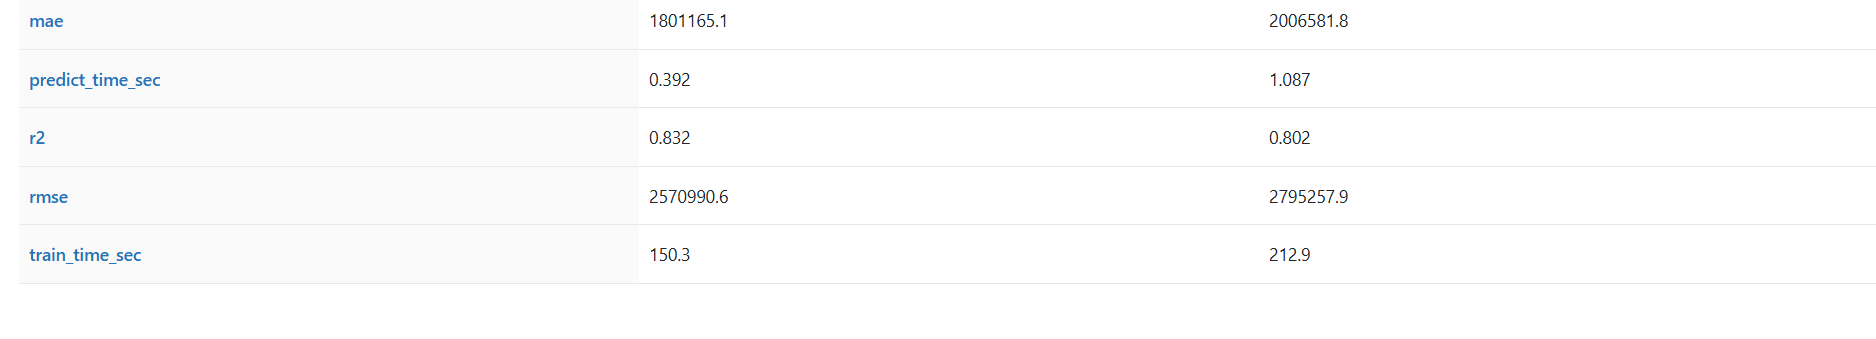

Новые метрики не улучшили сильно качество моделей.